# Detecting and removing cell-cycle-associated PCs

Cell-cycle activity is a common confounder in scRNA-seq analysis, particularly in developing tissues where many cells are actively proliferating. The shared cell-cycle transcriptional program can dominate principal components, obscuring cell-type identity and differentiation state.

PySingleCellNet provides tools to:

1. **Score** cells for a confounder gene set (e.g., cell-cycle genes)
2. **Correlate** those scores with individual PCs to find the confounded axes
3. **Automatically flag** PCs for removal using FDR and correlation thresholds
4. **Create new PCA embeddings** with the confounded PCs removed

This approach works for any confounder with a known gene signature -- cell cycle, mitochondrial stress, ribosomal content, etc.

#### Data

We use the [Pijuan-Sala et al. (2019)](https://doi.org/10.1038/s41586-019-0933-9) mouse gastrulation atlas, subsampled to ~15k cells for speed. This is a developmental dataset where cell-cycle variation is prominent, making it ideal for demonstrating confounder removal.

### Setup

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import pySingleCellNet as cn

### Load and subsample

In [2]:
adata_full = sc.read_h5ad("../../data/adPijuan_small.h5ad")
print(f"Full dataset: {adata_full.shape}")

# Subsample to ~15k cells, stratified by cell type
sc.pp.subsample(adata_full, n_obs=15000, random_state=42)
adata = adata_full.copy()
del adata_full
print(f"Subsampled: {adata.shape}")

Full dataset: (108857, 29329)
Subsampled: (15000, 29329)


### Preprocess

In [3]:
sc.pp.filter_genes(adata, min_cells=50)
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='seurat_v3', layer='counts')
sc.tl.pca(adata, mask_var='highly_variable')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata)

print(f"Cells: {adata.n_obs:,}  Genes: {adata.n_vars:,}  HVGs: {adata.var['highly_variable'].sum():,}")

Cells: 15,000  Genes: 14,360  HVGs: 2,000


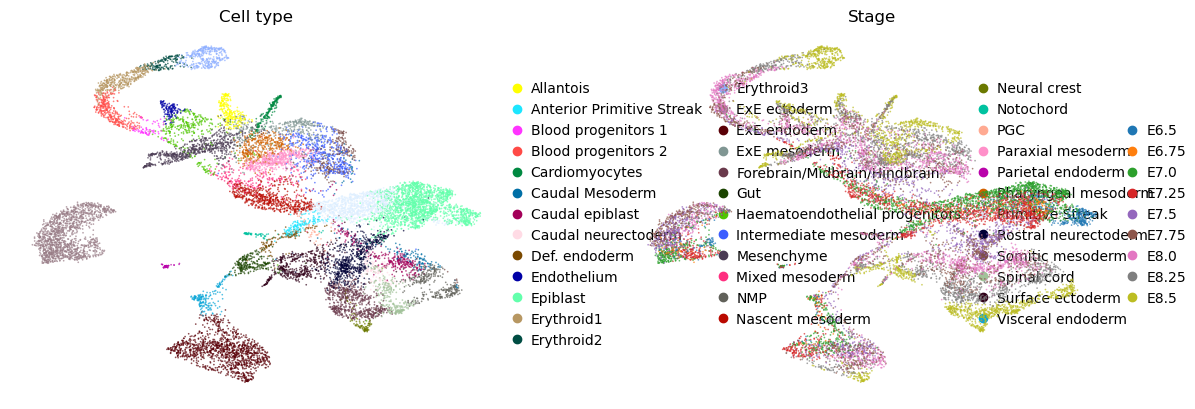

In [4]:
sc.pl.umap(
    adata,
    color=['celltype', 'stage'],
    frameon=False,
    legend_fontoutline=2,
    s=6,
    alpha=0.7,
    ncols=2,
    title=['Cell type', 'Stage'],
)

---
## Step 1: Load cell-cycle genes

We use a curated list of 115 mouse cell-cycle genes. Since this is a mouse dataset, the gene names match directly.

In [5]:
cc_genes = open("../../data/mouseCellCycle_050218.csv").read().strip().splitlines()
print(f"Loaded {len(cc_genes)} cell-cycle genes")
print(f"Examples: {', '.join(cc_genes[:8])}")

# How many are present in the data?
n_found = sum(1 for g in cc_genes if g in adata.var_names)
print(f"Found in adata: {n_found}/{len(cc_genes)}")

Loaded 114 cell-cycle genes
Examples: Mcm5, Pcna, Tyms, Fen1, Mcm2, Mcm4, Rrm1, Ung
Found in adata: 111/114


---
## Step 2: Score cells and correlate with PCs (the manual way)

Before using the automated function, let's walk through the individual steps to understand what's happening under the hood.

### 2a. Score cells for cell-cycle activity

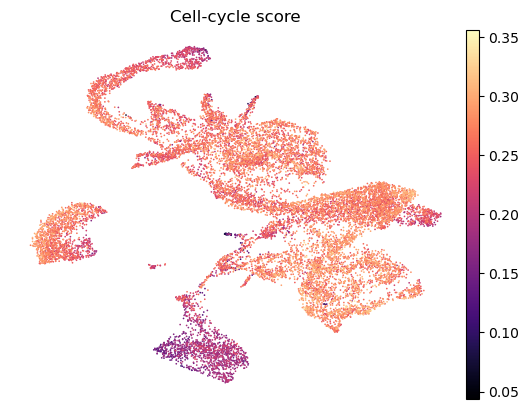

In [6]:
scores = cn.tl.score_gene_sets(
    adata,
    {'cell_cycle': cc_genes},
    return_dataframe=True,
)

adata.obs['cc_score'] = scores['cell_cycle'].values

sc.pl.umap(
    adata,
    color='cc_score',
    frameon=False,
    s=6,
    cmap='magma',
    title='Cell-cycle score',
)

### 2b. Correlate cell-cycle scores with PCs

The returned DataFrame includes:
- `fdr`: Benjamini-Hochberg adjusted p-values
- `impact_score`: correlation² × variance_ratio (how much total variance is attributable to the confounder through each PC)

In [7]:
corr_df = cn.tl.correlate_module_scores_with_pcs(
    adata,
    score_key='cc_score',
    method='pearson',
    min_abs_corr=0.3,
)

corr_df.head(10)

,pc,pc_index,correlation,abs_correlation,p_value,fdr,variance_ratio,impact_score,n_cells,score_key,flag_high_corr
0,PC1,1,-0.555222,0.555222,0.000000e+00,0.000000e+00,0.152098,0.046888,15000,cc_score,True
1,PC13,13,0.363421,0.363421,0.000000e+00,0.000000e+00,0.006393,0.000844,15000,cc_score,True
2,PC11,11,0.216764,0.216764,5.498684e-159,9.164474e-158,0.007475,0.000351,15000,cc_score,False
3,PC3,3,-0.209624,0.209624,1.388850e-148,1.736063e-147,0.060015,0.002637,15000,cc_score,False
4,PC12,12,-0.204527,0.204527,2.170761e-141,2.170761e-140,0.007033,0.000294,15000,cc_score,False
5,PC5,5,-0.150708,0.150708,6.468850e-77,5.390708e-76,0.024039,0.000546,15000,cc_score,False
6,PC9,9,-0.135260,0.135260,3.511907e-62,2.508505e-61,0.010213,0.000187,15000,cc_score,False
7,PC4,4,0.127717,0.127717,1.394504e-55,8.715653e-55,0.055283,0.000902,15000,cc_score,False
8,PC19,19,-0.122886,0.122886,1.468858e-51,8.160324e-51,0.004219,0.000064,15000,cc_score,False
9,PC6,6,-0.092255,0.092255,1.019710e-29,5.098550e-29,0.018253,0.000155,15000,cc_score,False


### 2c. Visualize the correlation landscape

PCs that exceed our thresholds (FDR < 0.05 and |r| >= 0.3) are highlighted in red.

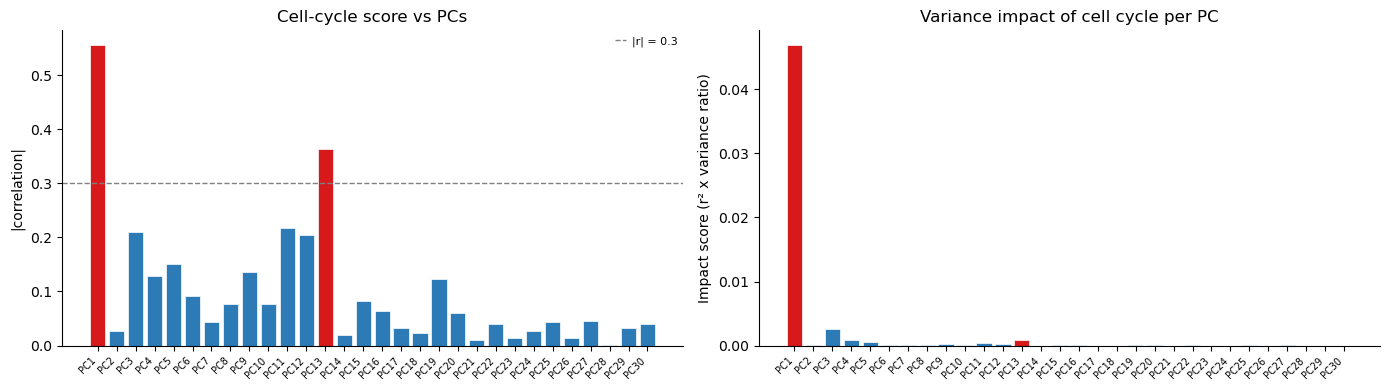

In [8]:
plot_df = corr_df.sort_values('pc_index').head(30)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

colors = ['#d7191c' if (row['fdr'] < 0.05 and row['abs_correlation'] >= 0.3) else '#2c7bb6'
          for _, row in plot_df.iterrows()]

# Left: absolute correlation per PC
axes[0].bar(range(len(plot_df)), plot_df['abs_correlation'].values, color=colors, edgecolor='white', linewidth=0.5)
axes[0].axhline(0.3, color='grey', linestyle='--', linewidth=1, label='|r| = 0.3')
axes[0].set_xticks(range(len(plot_df)))
axes[0].set_xticklabels(plot_df['pc'].values, rotation=45, ha='right', fontsize=7)
axes[0].set_ylabel('|correlation|')
axes[0].set_title('Cell-cycle score vs PCs')
axes[0].legend(fontsize=8)
axes[0].spines[['top', 'right']].set_visible(False)

# Right: impact score per PC
axes[1].bar(range(len(plot_df)), plot_df['impact_score'].values, color=colors, edgecolor='white', linewidth=0.5)
axes[1].set_xticks(range(len(plot_df)))
axes[1].set_xticklabels(plot_df['pc'].values, rotation=45, ha='right', fontsize=7)
axes[1].set_ylabel('Impact score (r² x variance ratio)')
axes[1].set_title('Variance impact of cell cycle per PC')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## Step 3: Automated PC flagging with `suggest_pcs_to_drop`

Instead of manually inspecting the correlation table, `suggest_pcs_to_drop` runs the full pipeline (score -> correlate -> threshold) and returns the flagged PCs.

| Parameter | Default | What it controls |
|---|---|---|
| `fdr_threshold` | 0.05 | Maximum FDR for a PC to be flagged |
| `min_abs_corr` | 0.3 | Minimum absolute correlation |
| `min_impact_score` | None | Optional: minimum impact score (r² x variance ratio) |
| `corr_method` | 'pearson' | 'pearson' or 'spearman' |

In [9]:
pcs_to_drop, diag_df = cn.tl.suggest_pcs_to_drop(
    adata,
    cc_genes,
    set_name='cell_cycle',
    fdr_threshold=0.05,
    min_abs_corr=0.3,
)

print(f"\nPCs to drop (1-indexed): {pcs_to_drop}")
print(f"\nDiagnostic table (top 5):")
diag_df.head()

suggest_pcs_to_drop: scored 15000 cells with 'cell_cycle' gene set
  -> flagged 2 PC(s) for removal: PC1, PC13
     (FDR < 0.05, |r| >= 0.3)

PCs to drop (1-indexed): [1, 13]

Diagnostic table (top 5):


,pc,pc_index,correlation,abs_correlation,p_value,fdr,variance_ratio,impact_score,n_cells,score_key,flag_high_corr
0,PC1,1,-0.555222,0.555222,0.000000e+00,0.000000e+00,0.152098,0.046888,15000,array,True
1,PC13,13,0.363421,0.363421,0.000000e+00,0.000000e+00,0.006393,0.000844,15000,array,True
2,PC11,11,0.216764,0.216764,5.498684e-159,9.164474e-158,0.007475,0.000351,15000,array,False
3,PC3,3,-0.209624,0.209624,1.388850e-148,1.736063e-147,0.060015,0.002637,15000,array,False
4,PC12,12,-0.204527,0.204527,2.170761e-141,2.170761e-140,0.007033,0.000294,15000,array,False


### Stricter filtering with impact score

To be more conservative, add `min_impact_score` so that only PCs that carry substantial variance *and* correlate with the confounder are flagged.

In [10]:
pcs_strict, _ = cn.tl.suggest_pcs_to_drop(
    adata,
    cc_genes,
    set_name='cell_cycle',
    fdr_threshold=0.05,
    min_abs_corr=0.3,
    min_impact_score=0.005,
)

print(f"PCs to drop (strict): {pcs_strict}")

suggest_pcs_to_drop: scored 15000 cells with 'cell_cycle' gene set
  -> flagged 1 PC(s) for removal: PC1
     (FDR < 0.05, |r| >= 0.3, impact >= 0.005)
PCs to drop (strict): [1]


---
## Step 4: Remove the confounded PCs

Use `drop_pcs_from_embedding` to create new PCA slots with those components excluded. This does *not* overwrite the original embedding -- it creates new keys.

In [11]:
if pcs_to_drop:
    new_keys = cn.ut.drop_pcs_from_embedding(adata, pcs_to_drop)
    print(f"New embedding keys: {new_keys}")
else:
    print("No PCs flagged for removal -- original embedding is retained.")
    new_keys = {'obsm': 'X_pca'}

New embedding keys: {'obsm': 'X_pca_noPC1_13', 'varm': 'PCs_noPC1_13', 'variance_ratio': 'variance_ratio_noPC1_13'}


---
## Step 5: One-liner with `remove_confounder_pcs`

`cn.ut.remove_confounder_pcs` combines scoring, flagging, and PC removal into a single call.

In [12]:
new_keys_auto, diag_auto = cn.ut.remove_confounder_pcs(
    adata,
    cc_genes,
    set_name='cell_cycle',
)

print(f"New keys: {new_keys_auto}")

suggest_pcs_to_drop: scored 15000 cells with 'cell_cycle' gene set
  -> flagged 2 PC(s) for removal: PC1, PC13
     (FDR < 0.05, |r| >= 0.3)
New keys: {'obsm': 'X_pca_noPC1_13', 'varm': 'PCs_noPC1_13', 'variance_ratio': 'variance_ratio_noPC1_13'}


---
## Step 6: Compare before and after

Rebuild the kNN graph and UMAP using the cleaned embedding, then compare side by side with the original.

In [13]:
# Use keys from the step-by-step approach (step 4)
clean_key = new_keys.get('obsm', 'X_pca')

if clean_key != 'X_pca':
    # Save original UMAP
    adata.obsm['X_umap_orig'] = adata.obsm['X_umap'].copy()

    # Rebuild neighbors and UMAP on the cleaned embedding
    n_pcs_clean = adata.obsm[clean_key].shape[1]
    sc.pp.neighbors(adata, n_neighbors=15, n_pcs=min(30, n_pcs_clean), use_rep=clean_key, key_added='neighbors_clean')
    sc.tl.umap(adata, neighbors_key='neighbors_clean')
    adata.obsm['X_umap_clean'] = adata.obsm['X_umap'].copy()

    print(f"Original PCs: {adata.obsm['X_pca'].shape[1]}, Cleaned PCs: {n_pcs_clean}")
else:
    print("No PCs were removed -- skipping comparison.")

Original PCs: 50, Cleaned PCs: 48


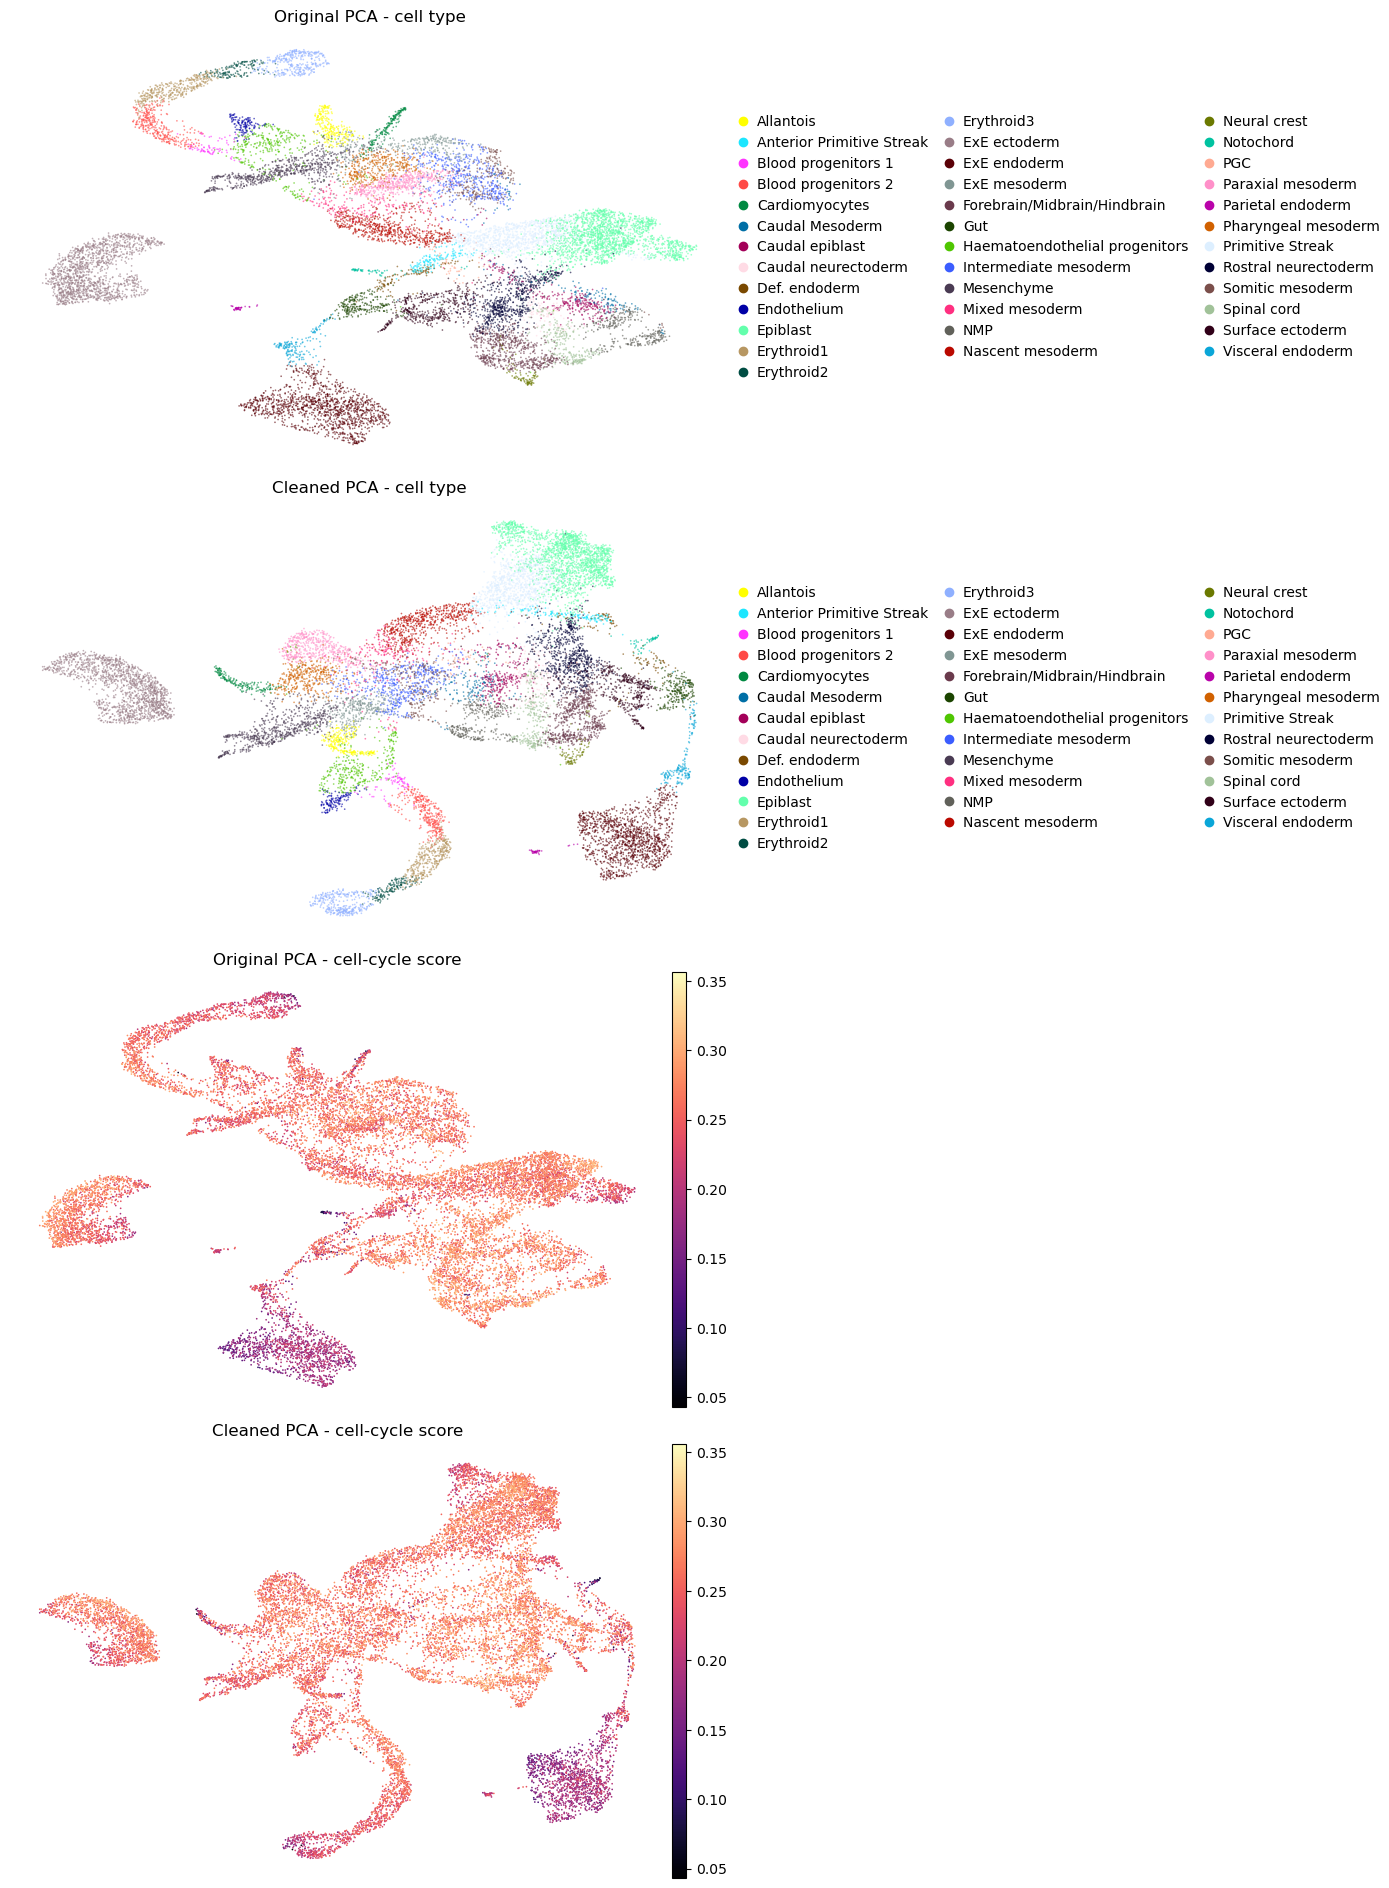

In [17]:
ssize = 6

if clean_key != 'X_pca':
    fig, axes = plt.subplots(4, 1, figsize=(14, 19))

    # Top row: cell type
    adata.obsm['X_umap'] = adata.obsm['X_umap_orig']
    sc.pl.umap(adata, color='celltype', ax=axes[0], show=False, frameon=False,
               legend_fontoutline=2, s=ssize, alpha=0.6, title='Original PCA - cell type')

    adata.obsm['X_umap'] = adata.obsm['X_umap_clean']
    sc.pl.umap(adata, color='celltype', ax=axes[1], show=False, frameon=False,
               legend_fontoutline=2, s=ssize, alpha=0.6, title='Cleaned PCA - cell type')

    # Bottom row: cell-cycle score
    adata.obsm['X_umap'] = adata.obsm['X_umap_orig']
    sc.pl.umap(adata, color='cc_score', ax=axes[2], show=False, frameon=False,
               s=ssize, cmap='magma', title='Original PCA - cell-cycle score')

    adata.obsm['X_umap'] = adata.obsm['X_umap_clean']
    sc.pl.umap(adata, color='cc_score', ax=axes[3], show=False, frameon=False,
               s=ssize, cmap='magma', title='Cleaned PCA - cell-cycle score')

    plt.tight_layout()
    plt.show()

    # Restore original UMAP
    adata.obsm['X_umap'] = adata.obsm['X_umap_orig']

---
## Summary

| Step | Function | What it does |
|---|---|---|
| Score cells | `cn.tl.score_gene_sets()` | Compute per-cell confounder activity |
| Correlate with PCs | `cn.tl.correlate_module_scores_with_pcs()` | Identify which PCs track the confounder |
| Flag PCs | `cn.tl.suggest_pcs_to_drop()` | Automatically select PCs using FDR + correlation thresholds |
| Remove PCs | `cn.ut.drop_pcs_from_embedding()` | Create a new embedding with flagged PCs excluded |
| All-in-one | `cn.ut.remove_confounder_pcs()` | Flag and remove in a single call |

**Tips:**

- The default thresholds (`fdr_threshold=0.05`, `min_abs_corr=0.3`) are a good starting point. Adjust `min_abs_corr` higher (e.g. 0.5) to be more conservative.
- Use `min_impact_score` to avoid removing PCs that correlate with the confounder but explain very little variance.
- Always inspect the diagnostic DataFrame to understand which PCs were flagged and why.
- This approach preserves the original PCA -- new keys are created, not overwritten.
- Works for any confounder with a known gene signature, not just cell cycle.
- For human data, use `case_insensitive=True` with mouse gene lists (or vice versa).